# Module 01 — Exercises — Solutions

These exercises practise the geometry of vectors from the [concept guide](README.md): norms, angles, cosine retrieval, projections, Gram–Schmidt, hyperplanes and the behaviour of random vectors in high dimension. The mini-project at the end builds a small recommender from user–user cosine similarity.

Only NumPy and matplotlib are needed. Where an exercise forbids a library call (e.g. `np.linalg.norm`), the point is to build the object from its definition once — afterwards, use the library.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def _safe(thunk):
    # Run thunk() and return None instead of raising; the check cells use this so they never crash.
    try:
        return thunk()
    except Exception:
        return None

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Three norms from their definitions  `★☆☆`

Implement `norms(v)` for a 1-D NumPy array `v`. It must return a tuple of three Python floats `(l1, l2, linf)`:

$$\|\mathbf{v}\|_1 = \sum_i |v_i|, \qquad \|\mathbf{v}\|_2 = \sqrt{\mathbf{v}\cdot\mathbf{v}}, \qquad \|\mathbf{v}\|_\infty = \max_i |v_i|.$$

Use only elementary NumPy (`np.abs`, `np.sum`, `np.sqrt`, `np.max`, `@`) — **no** `np.linalg.norm`.

In [3]:
def norms(v):
    # Return (l1, l2, linf) as Python floats, without np.linalg.norm.
    v = np.asarray(v, dtype=float)
    l1 = float(np.sum(np.abs(v)))
    l2 = float(np.sqrt(v @ v))
    linf = float(np.max(np.abs(v)))
    return (l1, l2, linf)

**Check your answer:**

In [4]:
v = np.array([3., -4., 12.])
got = _safe(lambda: norms(v))
check_close('L1 norm of (3, -4, 12) is 19', _safe(lambda: got[0]), 19.0)
check_close('L2 norm of (3, -4, 12) is 13', _safe(lambda: got[1]), 13.0)
check_close('L-infinity norm of (3, -4, 12) is 12', _safe(lambda: got[2]), 12.0)

z = np.random.default_rng(11).normal(size=50)
got_z = _safe(lambda: norms(z))
check_close('L2 agrees with np.linalg.norm on a random 50-vector', _safe(lambda: got_z[1]), np.linalg.norm(z))
check_hash('hidden: L1 norm of the random 50-vector', _safe(lambda: got_z[0]), '78ef8bff13f9c185')
check('ordering  Linf <= L2 <= L1  holds', _safe(lambda: got_z[2] <= got_z[1] <= got_z[0]))

✅ L1 norm of (3, -4, 12) is 19
✅ L2 norm of (3, -4, 12) is 13
✅ L-infinity norm of (3, -4, 12) is 12
✅ L2 agrees with np.linalg.norm on a random 50-vector
✅ hidden: L1 norm of the random 50-vector
✅ ordering  Linf <= L2 <= L1  holds


True

**Why this works**

Each norm is a one-liner once you read the definition literally: absolute values summed, squares summed and square-rooted (equivalently $\sqrt{\mathbf{v}\cdot\mathbf{v}}$), or the largest absolute value. The common wrong turns are forgetting the absolute value in the $L_1$ norm (negative entries would then cancel) and forgetting the square root in the $L_2$ norm (which returns the *squared* length). The ordering $\|\mathbf{v}\|_\infty \le \|\mathbf{v}\|_2 \le \|\mathbf{v}\|_1$ holds for every vector: the max is one of the terms in the sum of squares, and $\sqrt{\sum v_i^2} \le \sum |v_i|$ because the cross terms $2|v_i||v_j|$ are non-negative.

## Exercise 2 — Angle between two vectors  `★☆☆`

Implement `angle_between(u, v)` returning the angle in **degrees** (a float in $[0, 180]$) between two non-zero vectors, from

$$\cos\theta = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|}.$$

Floating-point rounding can push the cosine just above 1 — for $\mathbf{u} = \mathbf{v} = (1, 1, 1)$ the textbook formula gives $1.0000000000000002$ — and then `np.arccos` returns `nan`; clip the cosine to $[-1, 1]$ before taking the arc-cosine.

In [5]:
def angle_between(u, v):
    # Angle in degrees, in [0, 180]; clip the cosine so rounding noise cannot break arccos.
    u = np.asarray(u, dtype=float); v = np.asarray(v, dtype=float)
    c = (u @ v) / (np.sqrt(u @ u) * np.sqrt(v @ v))
    c = np.clip(c, -1.0, 1.0)
    return float(np.degrees(np.arccos(c)))

**Check your answer:**

In [6]:
check_close('angle between (3,4) and (4,3) is 16.26 degrees', _safe(lambda: angle_between(np.array([3., 4.]), np.array([4., 3.]))), 16.2602, tol=1e-3)
check_close('orthogonal vectors give 90 degrees', _safe(lambda: angle_between(np.array([1., 0.]), np.array([0., 1.]))), 90.0, tol=1e-6)
check_close('anti-parallel vectors give 180 degrees', _safe(lambda: angle_between(np.array([1., 2.]), np.array([-2., -4.]))), 180.0, tol=1e-6)
check_close('parallel vectors give 0 degrees', _safe(lambda: angle_between(np.array([0.1, 0.2, 0.3]), np.array([1., 2., 3.]))), 0.0, tol=1e-4)
check_close('(1,1,1) with itself gives 0 degrees (its rounded cosine is 1.0000000000000002: needs the clip)', _safe(lambda: angle_between(np.ones(3), np.ones(3))), 0.0, tol=1e-4)
check_hash('hidden: angle between (1,2,3) and (-1,0,1)', _safe(lambda: angle_between(np.array([1., 2., 3.]), np.array([-1., 0., 1.]))), 'bc0238ffc7f6e00b')

✅ angle between (3,4) and (4,3) is 16.26 degrees
✅ orthogonal vectors give 90 degrees
✅ anti-parallel vectors give 180 degrees
✅ parallel vectors give 0 degrees
✅ (1,1,1) with itself gives 0 degrees (its rounded cosine is 1.0000000000000002: needs the clip)
✅ hidden: angle between (1,2,3) and (-1,0,1)


True

**Why this works**

The geometric definition of the dot product, solved for $\theta$. The clip matters: for parallel vectors the computed cosine can be $1 + 10^{-16}$ — for $\mathbf{u} = \mathbf{v} = (1, 1, 1)$ the product of the two computed norms is $2.9999999999999996$, so the cosine comes out as $3/2.9999999999999996 = 1.0000000000000002$ — and `np.arccos` of anything outside $[-1, 1]$ is `nan`. Returning degrees rather than radians is just `np.degrees`. A frequent slip is to divide by $\|\mathbf{u}\|\|\mathbf{v}\|$ *after* the arc-cosine, or to divide by $\mathbf{u}\cdot\mathbf{u}$ (the squared norm) instead of the norm.

## Exercise 3 — Normalise the rows of an embedding table  `★☆☆`

Implement `normalize_rows(E)` for a 2-D array `E` of shape `(n, d)`: return an array of the same shape in which every non-zero row has been divided by its $L_2$ norm (so it becomes a unit vector) and every all-zero row is left as zeros (no division by zero, no `nan`). Use broadcasting — no Python loop over rows. `np.linalg.norm(..., axis=1, keepdims=True)` is allowed here.

In [7]:
def normalize_rows(E):
    # Each row divided by its L2 norm; all-zero rows are returned unchanged (as zeros).
    E = np.asarray(E, dtype=float)
    n = np.linalg.norm(E, axis=1, keepdims=True)
    return E / np.where(n == 0, 1.0, n)

**Check your answer:**

In [8]:
M = np.random.default_rng(5).normal(size=(6, 4)); M[2] = 0.0
got = _safe(lambda: normalize_rows(M))
check('output has the same shape as the input', _safe(lambda: got.shape == (6, 4)))
check_close('non-zero rows have norm 1', _safe(lambda: np.linalg.norm(got[[0, 1, 3, 4, 5]], axis=1)), np.ones(5))
check_close('the all-zero row stays zero (no nan)', _safe(lambda: got[2]), np.zeros(4))
check_close('directions are preserved (row 0 is a positive multiple of the original)', _safe(lambda: got[0] * np.linalg.norm(M[0])), M[0])
check_hash('hidden: sum of all entries of the normalised matrix', _safe(lambda: float(got.sum())), '94fe4f425bb6b309')

✅ output has the same shape as the input
✅ non-zero rows have norm 1
✅ the all-zero row stays zero (no nan)
✅ directions are preserved (row 0 is a positive multiple of the original)
✅ hidden: sum of all entries of the normalised matrix


True

**Why this works**

`np.linalg.norm(E, axis=1, keepdims=True)` gives an `(n, 1)` column of row norms, which broadcasts against `(n, d)` when you divide. The only subtlety is the zero row: dividing by zero produces `nan`, so replace zero norms by 1 before dividing (`np.where(n == 0, 1.0, n)`) — a zero vector has no direction, and leaving it at zero is the honest choice. Forgetting `keepdims=True` yields shape `(n,)`, which NumPy would try to broadcast along the *last* axis and fail (or silently do the wrong thing when `n == d`).

## Exercise 4 — Why cosine rather than Euclidean distance for text?  `★☆☆`

A colleague builds a document search engine on bag-of-words count vectors and ranks results by Euclidean distance to the query. A long, highly relevant article keeps ranking below short, barely related notes. Explain (a) what is going wrong geometrically, (b) why cosine similarity fixes it, (c) the exact relationship between cosine similarity and Euclidean distance *after* normalisation, and (d) one situation where you would deliberately keep the raw dot product or Euclidean distance instead.

**Answer**

(a) Count vectors scale with document length: a 3,000-word article on the query's topic points in (roughly) the same direction as a 300-word note but has about ten times the norm. Euclidean distance $\|\mathbf{q} - \mathbf{d}\|$ mixes two kinds of difference — direction (topic) and magnitude (length) — and for long documents the magnitude term dominates, so the relevant long article looks "far away" and an unrelated short note looks "close" (the guide's example: the football report beats the long ML article as neighbour of the ML note).

(b) Cosine similarity $\mathbf{q}\cdot\mathbf{d}/(\|\mathbf{q}\|\|\mathbf{d}\|)$ divides out both norms, so it depends only on the angle. Duplicating a document (doubling every count) leaves its cosine to every query unchanged.

(c) For unit vectors, $\|\hat{\mathbf{q}} - \hat{\mathbf{d}}\|^2 = 2 - 2\cos(\mathbf{q}, \mathbf{d})$, a monotone decreasing function of the cosine — so ranking by cosine is *identical* to ranking by Euclidean distance between the normalised vectors. The real choice is not "cosine versus Euclidean" but "normalise or not".

(d) Keep magnitude when it carries meaning: sensor readings or coordinates, where a larger vector really is a different state; embeddings trained with a metric loss that encodes confidence in the norm; or recommender item vectors whose length encodes popularity, where the raw dot product deliberately favours popular items. Attention scores also use the raw (scaled) dot product, because the model learns to use the norms of queries and keys.

## Exercise 5 — Top-k retrieval by cosine similarity  `★★☆`

Implement `top_k_cosine(E, q, k)`: given an embedding table `E` of shape `(n, d)` (no zero rows), a query vector `q` of shape `(d,)` and an integer `k`, return a NumPy integer array of the `k` row indices with the **largest cosine similarity** to `q`, in decreasing order of similarity.

Constraint: compute all `n` similarities with a **single matrix–vector product** (normalise the rows and the query first) — no Python loop over rows. `np.argsort` is allowed.

In [9]:
def top_k_cosine(E, q, k):
    # Indices of the k rows of E with the largest cosine similarity to q, best first.
    E = np.asarray(E, dtype=float); q = np.asarray(q, dtype=float)
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    scores = En @ (q / np.linalg.norm(q))          # all cosines in one matrix-vector product
    return np.argsort(-scores)[:k]

**Check your answer:**

In [10]:
E_small = np.array([[1., 0.], [0., 1.], [2., 0.1], [-1., 0.]])
q_small = np.array([1., 0.])
got = _safe(lambda: np.asarray(top_k_cosine(E_small, q_small, 2), dtype=int))
check_close('top-2 for the toy table is rows [0, 2] (row 2 is long but well aligned)', got, np.array([0, 2]))
got3 = _safe(lambda: np.asarray(top_k_cosine(E_small, 10 * q_small, 3), dtype=int))
check_close('scaling the query does not change the ranking', got3, np.array([0, 2, 1]))

g = np.random.default_rng(123); E_big = g.normal(size=(50, 8)); q_big = g.normal(size=8)
idx = _safe(lambda: np.asarray(top_k_cosine(E_big, q_big, 5), dtype=int))
check('returns exactly 5 indices', _safe(lambda: idx.shape == (5,)))
ref_scores = np.array([E_big[i] @ q_big / (np.linalg.norm(E_big[i]) * np.linalg.norm(q_big)) for i in range(50)])
check('similarities of the returned rows are in decreasing order', _safe(lambda: bool(np.all(np.diff(ref_scores[idx]) <= 0))))
check_hash('hidden: the five indices for the seeded table', idx, '4e648096ca66d1be')

✅ top-2 for the toy table is rows [0, 2] (row 2 is long but well aligned)
✅ scaling the query does not change the ranking
✅ returns exactly 5 indices
✅ similarities of the returned rows are in decreasing order
✅ hidden: the five indices for the seeded table


True

**Why this works**

Normalising the rows of $E$ and the query turns every cosine into a plain dot product, and the dot products of one vector with every row are exactly the matrix–vector product $\hat{E}\hat{\mathbf{q}}$ — one BLAS call instead of $n$ Python iterations. `np.argsort(-scores)[:k]` sorts in decreasing order (NumPy sorts ascending, hence the minus sign). Note that you do not even need to normalise the query to get the *ranking* right — dividing every score by the same positive constant changes nothing — but you do need to normalise the rows, otherwise long rows win. The toy table shows this: row 2 is twice as long as row 0 yet ranks second because its direction is slightly off.

## Exercise 6 — Projection and residual  `★★☆`

Implement `project(a, b)` returning a tuple `(p, r)` where `p` is the vector projection of `a` onto the line through `b` and `r = a - p` is the residual:

$$\mathbf{p} = \frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{b}\cdot\mathbf{b}}\,\mathbf{b}, \qquad \mathbf{r} = \mathbf{a} - \mathbf{p}.$$

Both outputs are NumPy arrays with the shape of `a`. Do **not** assume `b` is a unit vector.

In [11]:
def project(a, b):
    # Vector projection of a onto the line through b, and the residual a - p.
    a = np.asarray(a, dtype=float); b = np.asarray(b, dtype=float)
    p = (a @ b) / (b @ b) * b
    r = a - p
    return p, r

**Check your answer:**

In [12]:
a, b = np.array([2., 3.]), np.array([4., 2.])
got = _safe(lambda: project(a, b))
check_close('p for a=(2,3), b=(4,2) is (2.8, 1.4)', _safe(lambda: got[0]), np.array([2.8, 1.4]))
check_close('r for a=(2,3), b=(4,2) is (-0.8, 1.6)', _safe(lambda: got[1]), np.array([-0.8, 1.6]))

g = np.random.default_rng(3); a5, b5 = g.normal(size=5), 3.0 * g.normal(size=5)
got5 = _safe(lambda: project(a5, b5))
check_close('p + r reconstructs a (5-D random case)', _safe(lambda: got5[0] + got5[1]), a5)
check_close('residual is orthogonal to b (r . b = 0)', _safe(lambda: float(got5[1] @ b5)), 0.0, tol=1e-9)
check_close('p is parallel to b (cross-check: p = (p.b / b.b) b)', _safe(lambda: got5[0]), _safe(lambda: (got5[0] @ b5) / (b5 @ b5) * b5))
p4 = _safe(lambda: project(np.array([1., 2., 3., 4.]), np.array([1., 1., 0., 1.]))[0])
check_hash('hidden: fraction of ||a||^2 explained by b for a=(1,2,3,4), b=(1,1,0,1)', _safe(lambda: float((p4 @ p4) / 30.0)), 'dda4f1a7d6592081')

✅ p for a=(2,3), b=(4,2) is (2.8, 1.4)
✅ r for a=(2,3), b=(4,2) is (-0.8, 1.6)
✅ p + r reconstructs a (5-D random case)
✅ residual is orthogonal to b (r . b = 0)
✅ p is parallel to b (cross-check: p = (p.b / b.b) b)
✅ hidden: fraction of ||a||^2 explained by b for a=(1,2,3,4), b=(1,1,0,1)


True

**Why this works**

The coefficient $t^\star = \mathbf{a}\cdot\mathbf{b}/\mathbf{b}\cdot\mathbf{b}$ is the minimiser of $\|\mathbf{a} - t\mathbf{b}\|^2$, and multiplying it by $\mathbf{b}$ gives the closest point on the line. The residual is orthogonal by construction: $\mathbf{r}\cdot\mathbf{b} = \mathbf{a}\cdot\mathbf{b} - t^\star\,\mathbf{b}\cdot\mathbf{b} = 0$. The classic mistake is to write $(\mathbf{a}\cdot\mathbf{b})\,\mathbf{b}$ without the denominator, which is only right when $\|\mathbf{b}\| = 1$ — the 5-D check with $\mathbf{b}$ scaled by 3 would then fail by a factor of 9. The explained fraction $\|\mathbf{p}\|^2/\|\mathbf{a}\|^2$ equals $\cos^2\theta$, the $R^2$ of a one-variable regression through the origin.

## Exercise 7 — Gram–Schmidt orthonormalisation  `★★☆`

Implement `gram_schmidt(A)` for a matrix `A` of shape `(m, n)` with $n \le m$ linearly independent columns $\mathbf{a}_1, \dots, \mathbf{a}_n$. Return `Q` of the same shape whose columns are orthonormal and span the same space, built in order:

$$\mathbf{v}_j = \mathbf{a}_j - \sum_{i<j} (\mathbf{a}_j\cdot\mathbf{q}_i)\,\mathbf{q}_i, \qquad \mathbf{q}_j = \mathbf{v}_j / \|\mathbf{v}_j\|.$$

In code, subtract the projections one at a time from the running vector (so each dot product uses the partly reduced $\mathbf{v}_j$): this *modified* Gram–Schmidt gives the same result in exact arithmetic and loses less orthogonality to rounding. Because you build from $\mathbf{a}_j$ and only subtract, each $\mathbf{q}_j$ satisfies $\mathbf{q}_j\cdot\mathbf{a}_j > 0$ (so the signs are determined — `np.linalg.qr` may differ by a sign). Loops over columns are fine; do not call `np.linalg.qr` inside.

In [13]:
def gram_schmidt(A):
    # Columns of A (independent) -> Q with orthonormal columns, same span, q_j . a_j > 0.
    A = np.asarray(A, dtype=float)
    Q = np.zeros_like(A)
    for j in range(A.shape[1]):
        v = A[:, j].copy()
        for i in range(j):
            v = v - (v @ Q[:, i]) * Q[:, i]
        Q[:, j] = v / np.linalg.norm(v)
    return Q

**Check your answer:**

In [14]:
A = np.column_stack([[1., 1., 0.], [1., 0., 1.], [0., 1., 1.]])
Q = _safe(lambda: gram_schmidt(A))
check_close('Q^T Q = I for the 3x3 example', _safe(lambda: Q.T @ Q), np.eye(3), tol=1e-9)
check_close('first column is a1 / ||a1||', _safe(lambda: Q[:, 0]), np.array([1., 1., 0.]) / np.sqrt(2))
check_close('second column is (1, -1, 2) / sqrt(6)', _safe(lambda: Q[:, 1]), np.array([1., -1., 2.]) / np.sqrt(6))
check_close('agrees with np.linalg.qr up to column signs', _safe(lambda: np.abs(Q)), np.abs(np.linalg.qr(A)[0]), tol=1e-9)

A5 = np.random.default_rng(9).normal(size=(5, 3))
Q5 = _safe(lambda: gram_schmidt(A5))
check('shape is preserved for a 5x3 input', _safe(lambda: Q5.shape == (5, 3)))
check_close('Q^T Q = I for the 5x3 input', _safe(lambda: Q5.T @ Q5), np.eye(3), tol=1e-9)
check_close('same span: Q Q^T a = a for a column a of A', _safe(lambda: Q5 @ (Q5.T @ A5[:, 2])), A5[:, 2])
check('sign convention q_j . a_j > 0', _safe(lambda: bool(np.all(np.sum(Q5 * A5, axis=0) > 0))))
check_hash('hidden: sum of |Q| for the 5x3 input', _safe(lambda: float(np.abs(Q5).sum())), '0120b75034c2cea0')

✅ Q^T Q = I for the 3x3 example
✅ first column is a1 / ||a1||
✅ second column is (1, -1, 2) / sqrt(6)
✅ agrees with np.linalg.qr up to column signs
✅ shape is preserved for a 5x3 input
✅ Q^T Q = I for the 5x3 input
✅ same span: Q Q^T a = a for a column a of A
✅ sign convention q_j . a_j > 0
✅ hidden: sum of |Q| for the 5x3 input


True

**Why this works**

Each step is the projection exercise applied repeatedly: subtracting $(\mathbf{v}\cdot\mathbf{q}_i)\,\mathbf{q}_i$ removes exactly the component along $\mathbf{q}_i$, and because the earlier $\mathbf{q}_i$ are mutually orthogonal, removing one component never re-introduces another. Normalising at the end makes the length 1. Using the running vector $\mathbf{v}$ (rather than the original $\mathbf{a}_j$) in each dot product is the *modified* Gram–Schmidt variant, which loses less orthogonality to rounding. The usual bugs: normalising before subtracting, subtracting projections onto the un-normalised $\mathbf{a}_i$ instead of $\mathbf{q}_i$, or mutating `A` in place (hence the `.copy()`).

## Exercise 8 — Signed distance to a hyperplane, vectorised  `★★☆`

Implement `signed_distance(X, w, b)` for a data matrix `X` of shape `(n, d)`, a normal vector `w` of shape `(d,)` and a scalar `b`. Return the array of shape `(n,)` of signed distances of every row to the hyperplane $\mathbf{w}\cdot\mathbf{x} + b = 0$:

$$\delta(\mathbf{x}) = \frac{\mathbf{w}\cdot\mathbf{x} + b}{\|\mathbf{w}\|}.$$

No Python loop over rows — one matrix–vector product.

In [15]:
def signed_distance(X, w, b):
    # Signed distance of every row of X (shape (n, d)) to the hyperplane w.x + b = 0 -> shape (n,).
    X = np.asarray(X, dtype=float); w = np.asarray(w, dtype=float)
    return (X @ w + b) / np.linalg.norm(w)

**Check your answer:**

In [16]:
w, b = np.array([3., 4.]), -12.0
pts = np.array([[4., 3.], [0., 0.], [2., 1.5]])
got = _safe(lambda: signed_distance(pts, w, b))
check_close('distances for the guide example are (2.4, -2.4, 0)', got, np.array([2.4, -2.4, 0.0]))
check_close('rescaling (w, b) by 10 changes nothing', _safe(lambda: signed_distance(pts, 10 * w, 10 * b)), got)
check('output shape is (n,)', _safe(lambda: got.shape == (3,)))

P = np.random.default_rng(21).normal(size=(200, 3)); w3, b3 = np.array([1., -2., 2.]), 0.5
sd = _safe(lambda: signed_distance(P, w3, b3))
check_hash('hidden: number of points on the positive side', _safe(lambda: int(np.sum(sd > 0))), '3038bfb575bee6a0')
check_hash('hidden: distance of the point closest to the plane', _safe(lambda: float(np.min(np.abs(sd)))), '8d938122d3904436')

✅ distances for the guide example are (2.4, -2.4, 0)
✅ rescaling (w, b) by 10 changes nothing
✅ output shape is (n,)
✅ hidden: number of points on the positive side
✅ hidden: distance of the point closest to the plane


True

**Why this works**

`X @ w` computes $\mathbf{w}\cdot\mathbf{x}$ for every row at once; adding `b` broadcasts the scalar; dividing by $\|\mathbf{w}\|$ converts raw scores into geometric distances. The sign tells you the side (positive where $\mathbf{w}$ points), and the invariance check matters conceptually: $(10\mathbf{w}, 10b)$ is the *same* hyperplane, so a classifier's confidence should be read from the distance, not from the raw score. Forgetting to divide by $\|\mathbf{w}\|$ gives the raw score — fine for the predicted label, wrong for the margin.

## Exercise 9 — Predict the effect of the square root of d_k in attention  `★★☆`

In a transformer, the attention weight of key $j$ for query $i$ is $\operatorname{softmax}_j(\mathbf{q}_i\cdot\mathbf{k}_j / \sqrt{d_k})$. Suppose the coordinates of $\mathbf{q}$ and $\mathbf{k}$ are independent with mean 0 and variance 1, and $d_k = 512$.

(a) What are the mean and standard deviation of the raw score $\mathbf{q}\cdot\mathbf{k}$? (b) Predict what the softmax over 20 keys looks like with raw scores, and what goes wrong for learning. (c) Why divide by $\sqrt{d_k}$ specifically, rather than by $d_k$?

**Answer**

(a) $\mathbf{q}\cdot\mathbf{k} = \sum_{i=1}^{d_k} q_i k_i$ is a sum of $d_k$ independent terms, each with mean $\mathbb{E}[q_i]\mathbb{E}[k_i] = 0$ and variance $\mathbb{E}[q_i^2]\mathbb{E}[k_i^2] = 1$. So the raw score has mean 0 and variance $d_k$, i.e. standard deviation $\sqrt{512} \approx 22.6$.

(b) Twenty raw scores spread over roughly $\pm 45$ differ from each other by tens of units; after exponentiation the largest dominates completely and the softmax is essentially one-hot. The attention weights then barely depend on the other keys, and the gradient through the softmax — whose Jacobian entries are proportional to $p_j(1 - p_j)$ — is nearly zero: the layer stops learning (saturation).

(c) Dividing by $\sqrt{d_k}$ brings the standard deviation back to exactly 1 regardless of $d_k$, so the softmax operates in its sensitive range for any head size. Dividing by $d_k$ would shrink the scores to standard deviation $1/\sqrt{d_k} \approx 0.044$: all weights become nearly equal and attention cannot discriminate between keys. $\sqrt{d_k}$ is the unique scale that removes the dependence on dimension — the same $1/\sqrt d$ that governs the cosine of random vectors in the lesson's simulation.

## Exercise 10 — Distance concentration experiment  `★★★`

Implement `distance_concentration(d, n=500, seed=0)`:

1. Create `g = np.random.default_rng(seed)` and sample `n` points uniformly in the unit cube $[0, 1]^d$ with `g.random((n, d))`.
2. Compute the Euclidean distances from the **first** point to the other `n - 1` points.
3. Return the tuple `(contrast, rel_std_sq)` where `contrast = (max - min) / min` of those distances and `rel_std_sq` is the standard deviation divided by the mean of the **squared** distances.

Theory says `rel_std_sq` $\approx 1.18/\sqrt d$ and that `contrast` collapses towards 0 as $d$ grows. The checks test these qualitative facts, not exact numbers, so you may use `np.linalg.norm`.

In [17]:
def distance_concentration(d, n=500, seed=0):
    # Sample n points uniformly in [0,1]^d, measure distances from the first point to the others.
    g = np.random.default_rng(seed)
    P = g.random((n, d))
    dist = np.linalg.norm(P[1:] - P[0], axis=1)
    contrast = float((dist.max() - dist.min()) / dist.min())
    sq = dist ** 2
    rel_std_sq = float(sq.std() / sq.mean())
    return contrast, rel_std_sq

**Check your answer:**

In [18]:
res = {d: _safe(lambda d=d: distance_concentration(d)) for d in (2, 10, 100, 1000)}
check('returns a pair (contrast, rel_std_sq)', _safe(lambda: len(res[2]) == 2))
check('in 2-D the farthest neighbour is more than twice as far as the nearest (contrast > 1)', _safe(lambda: res[2][0] > 1.0))
check('in 1000-D nearest and farthest differ by less than 35% (contrast < 0.35)', _safe(lambda: res[1000][0] < 0.35))
check('contrast decreases monotonically for d = 2, 10, 100, 1000', _safe(lambda: res[2][0] > res[10][0] > res[100][0] > res[1000][0]))
check('relative spread of squared distances at d = 100 is close to 1.18 / sqrt(100) = 0.118', _safe(lambda: 0.08 < res[100][1] < 0.16))
check('relative spread shrinks by roughly sqrt(10) from d = 100 to d = 1000', _safe(lambda: 2.0 < res[100][1] / res[1000][1] < 5.0))

✅ returns a pair (contrast, rel_std_sq)
✅ in 2-D the farthest neighbour is more than twice as far as the nearest (contrast > 1)
✅ in 1000-D nearest and farthest differ by less than 35% (contrast < 0.35)
✅ contrast decreases monotonically for d = 2, 10, 100, 1000
✅ relative spread of squared distances at d = 100 is close to 1.18 / sqrt(100) = 0.118
✅ relative spread shrinks by roughly sqrt(10) from d = 100 to d = 1000


True

**Why this works**

The squared distance is $\sum_{i=1}^d (x_i - y_i)^2$, a sum of $d$ independent terms with mean $1/6$ and variance $7/180$, so its mean grows like $d$ while its standard deviation grows like $\sqrt d$ — the relative spread is $\sqrt{7/180}\,/\,(1/6)\,/\sqrt d \approx 1.18/\sqrt d$. With all distances squeezed into a band of relative width $\sim 1/\sqrt d$, the gap between the nearest and the farthest neighbour collapses too: that is the `contrast` you measured. Two practical notes: `P[1:] - P[0]` broadcasts the first point against all others in one step, and distances from a single reference point are enough — using all $\binom{n}{2}$ pairs gives the same picture with more correlated samples.

## Exercise 11 — Reflect points across a hyperplane  `★★★`

Implement `reflect(X, w, b)` returning, for every row $\mathbf{x}$ of `X` (shape `(n, d)`), its mirror image across the hyperplane $\mathbf{w}\cdot\mathbf{x} + b = 0$:

$$\mathbf{x}' = \mathbf{x} - 2\,\delta(\mathbf{x})\,\hat{\mathbf{w}}, \qquad \delta(\mathbf{x}) = \frac{\mathbf{w}\cdot\mathbf{x} + b}{\|\mathbf{w}\|}, \quad \hat{\mathbf{w}} = \frac{\mathbf{w}}{\|\mathbf{w}\|}.$$

Return an array of shape `(n, d)`; vectorise with broadcasting (hint: `delta[:, None]`). Reflecting twice must give back `X`, and the signed distance of the reflected points must be the negative of the original.

In [19]:
def reflect(X, w, b):
    # Mirror image of every row of X across the hyperplane w.x + b = 0.
    X = np.asarray(X, dtype=float); w = np.asarray(w, dtype=float)
    w_hat = w / np.linalg.norm(w)
    delta = (X @ w + b) / np.linalg.norm(w)            # signed distances, shape (n,)
    return X - 2.0 * delta[:, None] * w_hat

**Check your answer:**

In [20]:
w, b = np.array([3., 4.]), -12.0
pts = np.array([[4., 3.], [2., 1.5], [0., 0.]])
got = _safe(lambda: reflect(pts, w, b))
check_close('(4,3) reflects to (1.12, -0.84) across 3x + 4y = 12', _safe(lambda: got[0]), np.array([1.12, -0.84]))
check_close('a point on the plane is its own mirror image', _safe(lambda: got[1]), np.array([2., 1.5]))
check_close('reflecting twice is the identity', _safe(lambda: reflect(got, w, b)), pts)
_sd = lambda Z: (Z @ w + b) / np.linalg.norm(w)
check_close('signed distances flip sign', _safe(lambda: _sd(got)), -_sd(pts))

P = np.random.default_rng(33).normal(size=(20, 5)); w5, b5 = np.array([1., 2., 0., -1., 3.]), -0.7
R5 = _safe(lambda: reflect(P, w5, b5))
check('shape (20, 5) is preserved', _safe(lambda: R5.shape == (20, 5)))
check_close('reflection preserves distances between points (it is an isometry)', _safe(lambda: np.linalg.norm(R5[0] - R5[1])), np.linalg.norm(P[0] - P[1]))
check_hash('hidden: sum of all reflected coordinates (5-D seeded case)', _safe(lambda: float(R5.sum())), '6e2f6a21a1ca06f6')

✅ (4,3) reflects to (1.12, -0.84) across 3x + 4y = 12
✅ a point on the plane is its own mirror image
✅ reflecting twice is the identity
✅ signed distances flip sign
✅ shape (20, 5) is preserved
✅ reflection preserves distances between points (it is an isometry)
✅ hidden: sum of all reflected coordinates (5-D seeded case)


True

**Why this works**

Moving a point by $-\delta(\mathbf{x})\hat{\mathbf{w}}$ drops it onto the hyperplane (the foot of the perpendicular); moving it by twice that lands on the mirror image. The signed distance is a scalar per row, so `delta[:, None] * w_hat` broadcasts an `(n, 1)` column against the `(d,)` normal to produce the `(n, d)` correction. Reflections are isometries (they preserve all distances and angles) and are their own inverse; in matrix form the map is $I - 2\hat{\mathbf{w}}\hat{\mathbf{w}}^\top$, a *Householder reflection* — exactly what `np.linalg.qr` uses internally instead of Gram–Schmidt, which is why its signs can differ from yours in the previous exercise.

## Exercise 12 — Mini-project — a tiny recommender from cosine similarity  `★★★`

Build a user-based collaborative-filtering recommender on a synthetic users × items ratings matrix and evaluate it honestly.

The starter cell generates the data: 80 users, 30 items, ratings 1–5 of which about 70% are observed; roughly a fifth of the observed ratings are hidden in `test_mask` for evaluation, the rest are in `train_mask` / `R_train` (0 marks "unknown"). The ratings come from hidden user tastes and item profiles (a dot product, as in Section 3 of the guide) plus a per-user generosity bias, a per-item popularity bias and noise.

1. **Baselines.** Predict every held-out rating by the global mean of the training ratings, then by each user's own mean. Report the RMSE of each.
2. **Similarity.** Mean-centre each user's training row (subtract that user's mean from their known ratings; unknown entries stay 0) and compute the full user–user cosine-similarity matrix with one matrix product.
3. **Prediction.** For a held-out pair (user $u$, item $i$), take the $k$ most similar users who *have* rated item $i$ and predict $u$'s own mean plus the similarity-weighted average of those neighbours' deviations from their means. Fall back to the user mean when no neighbour qualifies. Clip to $[1, 5]$.
4. **Evaluation.** Compute the RMSE on the held-out ratings for several $k$ (e.g. 1, 2, 3, 5, 8, 12, 20, 40, all) and plot RMSE against $k$ with the two baselines as horizontal lines (a logarithmic $k$ axis suits this spacing).

**Rubric — you have mastered this when you can:**

- Compute both baselines and state their RMSE before touching similarities — a recommender that does not beat the user-mean baseline is not working.
- Explain why the rows are mean-centred before computing cosine (it turns cosine into a Pearson-style correlation and stops "generous raters" looking similar to everyone).
- Obtain the whole similarity matrix with one matrix product of row-normalised data, and zero the diagonal so a user is not their own neighbour.
- Use only neighbours who actually rated the item, weight by similarity, and handle the empty-neighbour case without crashing.
- Produce the RMSE-versus-$k$ plot with titled axes and read it: very small $k$ is noisy, very large $k$ averages in dissimilar users, the best $k$ is in between.
- Say what you would change for real data (sparsity, shrinkage of similarities computed on few co-rated items, item–item variant, matrix factorisation — Module 03).

**Solution sketch**

Mean-centring makes the cosine between two users depend only on how they deviate from their personal averages, so a user who rates everything 4–5 and one who rates everything 2–3 but with the same *pattern* become similar. With zeros for unknown entries, $\hat{C}\hat{C}^\top$ gives every pairwise cosine in one product (unrated items contribute nothing). Prediction adds the similarity-weighted average of the neighbours' centred ratings back onto the target user's mean; only positively similar users are used. On this data the user-mean baseline improves a little on the global mean (it captures the generosity bias), and the recommender beats both clearly for moderate $k$ (RMSE around 0.74 at $k \approx 8$ versus 1.10 for the user mean); the curve rises again for large $k$ as dissimilar users are averaged in, and $k = 1$ is noisy because a single neighbour's rating carries all the weight. The remaining error comes from the rounding noise in the ratings and from the item bias, which user-based CF only captures indirectly — an item–item variant or matrix factorisation (Module 03) would pick it up.

train ratings: 1384  test ratings: 320
RMSE global mean : 1.154
RMSE user mean   : 1.102
k =  1 neighbours: RMSE = 0.947
k =  2 neighbours: RMSE = 0.809
k =  3 neighbours: RMSE = 0.764
k =  5 neighbours: RMSE = 0.751
k =  8 neighbours: RMSE = 0.742
k = 12 neighbours: RMSE = 0.752
k = 20 neighbours: RMSE = 0.765
k = 40 neighbours: RMSE = 0.787
k = 79 neighbours: RMSE = 0.787


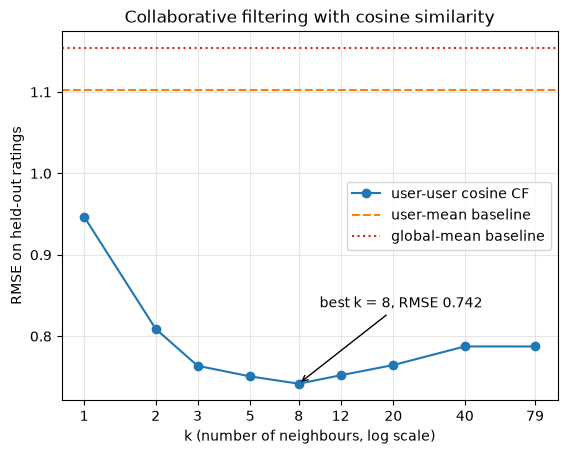

In [21]:
g = np.random.default_rng(7)
n_users, n_items, n_factors = 80, 30, 3
U_true = g.normal(size=(n_users, n_factors))
V_true = g.normal(size=(n_items, n_factors))
user_bias = g.normal(scale=0.5, size=n_users)
item_bias = g.normal(scale=0.5, size=n_items)
R_full = np.clip(np.round(3.2 + user_bias[:, None] + item_bias[None, :]
                          + (U_true @ V_true.T) / np.sqrt(n_factors)
                          + g.normal(scale=0.4, size=(n_users, n_items))), 1, 5)
observed = g.random((n_users, n_items)) < 0.7
test_mask = observed & (g.random((n_users, n_items)) < 0.2)
train_mask = observed & ~test_mask
R_train = np.where(train_mask, R_full, 0.0)
print("train ratings:", train_mask.sum(), " test ratings:", test_mask.sum())

def rmse(pred, truth):
    return float(np.sqrt(np.mean((pred - truth) ** 2)))

test_u, test_i = np.where(test_mask)
truth = R_full[test_mask]

# --- baselines ---------------------------------------------------------------------------------
global_mean = R_train[train_mask].mean()
counts = train_mask.sum(axis=1)
user_mean = np.where(counts > 0, R_train.sum(axis=1) / np.maximum(counts, 1), global_mean)
print("RMSE global mean : %.3f" % rmse(np.full(len(truth), global_mean), truth))
print("RMSE user mean   : %.3f" % rmse(user_mean[test_u], truth))

# --- user-user cosine similarity on mean-centred rows ------------------------------------------
C = np.where(train_mask, R_train - user_mean[:, None], 0.0)      # centred, unknown -> 0
norms = np.linalg.norm(C, axis=1, keepdims=True)
Cn = C / np.where(norms == 0, 1.0, norms)
S = Cn @ Cn.T                                                     # (n_users x n_users) cosine matrix
np.fill_diagonal(S, 0.0)                                          # a user is not their own neighbour

def predict(u, i, k):
    rated = train_mask[:, i].copy(); rated[u] = False             # users who rated item i (not u)
    cand = np.where(rated)[0]
    if len(cand) == 0:
        return user_mean[u]
    sims = S[u, cand]
    top = cand[np.argsort(-sims)[:k]]
    w = S[u, top]
    w = np.where(w > 0, w, 0.0)                                   # ignore dissimilar users
    if w.sum() == 0:
        return user_mean[u]
    # weighted average of the neighbours' *deviations* from their own means, added to u's mean
    return user_mean[u] + np.sum(w * (R_train[top, i] - user_mean[top])) / w.sum()

ks = [1, 2, 3, 5, 8, 12, 20, 40, n_users - 1]
scores = []
for k in ks:
    pred = np.clip([predict(u, i, k) for u, i in zip(test_u, test_i)], 1, 5)
    scores.append(rmse(np.array(pred), truth))
    print("k = %2d neighbours: RMSE = %.3f" % (k, scores[-1]))

fig, ax = plt.subplots()
ax.plot(ks, scores, "o-", label="user-user cosine CF")
ax.axhline(rmse(user_mean[test_u], truth), color="C1", ls="--", label="user-mean baseline")
ax.axhline(rmse(np.full(len(truth), global_mean), truth), color="C3", ls=":", label="global-mean baseline")
best = int(np.argmin(scores))
ax.annotate(f"best k = {ks[best]}, RMSE {scores[best]:.3f}", (ks[best], scores[best]), xytext=(15, 55), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"))
ax.set_xscale("log"); ax.set_xticks(ks); ax.set_xticklabels([str(k) for k in ks]); ax.minorticks_off()   # small k is where the action is
ax.set_xlabel("k (number of neighbours, log scale)"); ax.set_ylabel("RMSE on held-out ratings"); ax.set_title("Collaborative filtering with cosine similarity")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Score

In [22]:
summary()


Score: 55/55 checks passed  🎉
